# Классификация обращений с помощью рекуррентных сетей

Сравнение RNN, LSTM и GRU для классификации русскоязычных обращений. Ноутбук содержит обработку текста, обучение, оценку и сводное сравнение моделей.

In [1]:
import re
import pymorphy3
import pandas as pd
from sklearn.model_selection import train_test_split
from razdel import tokenize
from navec import Navec
import numpy as np
import torch

In [15]:
seed = 42
np.random.seed(seed)

# 1. Загружаем датасет
Возьмём его часть (половину)

In [2]:
ds = pd.read_csv(r'../../data/petitions.csv')

In [3]:
ds.head()

,id,public_petition_text,reason_category
0,3168490,снег на дороге,Благоустройство
1,3219678,очистить кабельный киоск от рекламы,Благоустройство
2,2963920,"Просим убрать все деревья и кустарники, которы...",Благоустройство
3,3374910,Неудовлетворительное состояние парадной - надп...,Содержание МКД
4,3336285,Граффити,Благоустройство


In [4]:
ds = ds.drop(columns=['id'], axis=1)

In [5]:
ds['reason_category'].value_counts()

reason_category
Благоустройство                                                                     34769
Содержание МКД                                                                      14461
Нарушение правил пользования общим имуществом                                        2170
Незаконная информационная и (или) рекламная конструкция                              1831
Фасад                                                                                1483
Повреждения или неисправность элементов уличной инфраструктуры                       1164
Кровля                                                                                825
Водоснабжение                                                                         809
Состояние рекламных или информационных конструкций                                    673
Санитарное состояние                                                                  434
Центральное отопление                                                               

In [6]:
top_classes = ds['reason_category'].value_counts().head(2).index

frames = []
for cls, group in ds.groupby('reason_category'):
    if cls in top_classes:
        group = group.sample(frac=0.3, random_state=42)  # оставить половину
    frames.append(group)

ds_sample = pd.concat(frames)

In [7]:
ds_sample['reason_category'].value_counts()

reason_category
Благоустройство                                                                     10431
Содержание МКД                                                                       4338
Нарушение правил пользования общим имуществом                                        2170
Незаконная информационная и (или) рекламная конструкция                              1831
Фасад                                                                                1483
Повреждения или неисправность элементов уличной инфраструктуры                       1164
Кровля                                                                                825
Водоснабжение                                                                         809
Состояние рекламных или информационных конструкций                                    673
Санитарное состояние                                                                  434
Центральное отопление                                                               

In [8]:
ds_sample.head()

,public_petition_text,reason_category
57338,упавшее дерево,Благоустройство
21420,Повреждена решетка стока.,Благоустройство
39101,"Неубранный снег на проезжей части и там, где ...",Благоустройство
7870,Прошу установить по лежачему полицейскому с ка...,Благоустройство
42523,объявления на знаках,Благоустройство


# 2. Выполним предобработку данных

In [9]:
ds_sample['public_petition_text'] = ds_sample['public_petition_text'].map(lambda x: re.sub(r'[^а-яё\s]', '', x, flags=re.IGNORECASE))

In [10]:
ds_sample['public_petition_text'] = ds_sample['public_petition_text'].map(lambda x: x.lower())

In [11]:
ds_sample['public_petition_text'] = ds_sample['public_petition_text'].map(lambda x: re.sub(r'\s+', ' ', x).strip())

In [12]:
ds_sample['public_petition_text'] = ds_sample['public_petition_text'].map(lambda x: '\n'.join([line.strip() for line in x.split('\n')]))

In [13]:
ds_sample.head()

,public_petition_text,reason_category
57338,упавшее дерево,Благоустройство
21420,повреждена решетка стока,Благоустройство
39101,неубранный снег на проезжей части и там где па...,Благоустройство
7870,прошу установить по лежачему полицейскому с ка...,Благоустройство
42523,объявления на знаках,Благоустройство


In [14]:
def get_tokens(string):
    tokens = list(tokenize(string))
    return [_.text for _ in tokens]

In [15]:
print(get_tokens("tiktoken is great!"))

['tiktoken', 'is', 'great', '!']


# 3. Выполним токенизацию 

In [16]:
ds_sample['public_petition_text'] = ds_sample['public_petition_text'].map(lambda x: get_tokens(x))

In [17]:
ds_sample.head()

,public_petition_text,reason_category
57338,"[упавшее, дерево]",Благоустройство
21420,"[повреждена, решетка, стока]",Благоустройство
39101,"[неубранный, снег, на, проезжей, части, и, там...",Благоустройство
7870,"[прошу, установить, по, лежачему, полицейскому...",Благоустройство
42523,"[объявления, на, знаках]",Благоустройство


In [18]:
morph = pymorphy3.MorphAnalyzer()
def lemmatize_words(words: list) -> list:
    return [morph.parse(word)[0].normal_form for word in words]

In [19]:
ds_sample['public_petition_text'] = ds_sample['public_petition_text'].map(lambda x: lemmatize_words(x))

In [20]:
ds_sample.head()

,public_petition_text,reason_category
57338,"[упавший, дерево]",Благоустройство
21420,"[повредить, решётка, сток]",Благоустройство
39101,"[неубранный, снег, на, проезжий, часть, и, там...",Благоустройство
7870,"[просить, установить, по, лежачий, полицейский...",Благоустройство
42523,"[объявление, на, знак]",Благоустройство


# 4. Выполним векторизацию каждого токена в документе

In [21]:
path = '../../data/navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)

In [22]:
def vectorize_tokens(tokens):
    embeddings = []
    for token in tokens:
        if token in navec:
            embeddings.append(navec[token])
        else:
            embeddings.append(navec['<unk>'])
    return embeddings

In [23]:
ds_sample['public_petition_text'] = ds_sample['public_petition_text'].map(lambda x: vectorize_tokens(x))

In [24]:
print(len(ds_sample['public_petition_text'].iloc[0]))
print(len(ds_sample['public_petition_text'].iloc[0][0]))

2
300


In [25]:
ds_sample.head()

,public_petition_text,reason_category
57338,"[[0.018231504, -0.18105331, 0.28123152, 0.0011...",Благоустройство
21420,"[[0.18687034, 0.51466656, 0.42237148, -0.03852...",Благоустройство
39101,"[[0.19214402, -0.1959362, 0.43695402, -0.40299...",Благоустройство
7870,"[[0.05624003, -0.4158787, -0.039217323, 0.1260...",Благоустройство
42523,"[[-0.34724313, -0.14704202, -0.4983434, 0.0336...",Благоустройство


# 5. Закодируем значения целевого признака

In [26]:
from sklearn.preprocessing import LabelEncoder

In [27]:
le = LabelEncoder()
le.fit(ds_sample['reason_category'])
le.classes_

array(['Благоустройство', 'Водоотведение', 'Водоснабжение', 'Кровля',
       'Нарушение порядка пользования общим имуществом',
       'Нарушение правил пользования общим имуществом',
       'Незаконная информационная и (или) рекламная конструкция',
       'Незаконная реализация товаров с торгового оборудования (прилавок, ящик, с земли)',
       'Повреждения или неисправность элементов уличной инфраструктуры',
       'Подвалы', 'Санитарное состояние', 'Содержание МКД',
       'Состояние рекламных или информационных конструкций', 'Фасад',
       'Центральное отопление'], dtype=object)

In [28]:
ds_encoded = ds_sample.copy()
encoded_data = le.transform(ds_sample['reason_category'])
ds_encoded['reason_category'] = encoded_data

In [29]:
mapping = dict(zip(range(len(le.classes_)), le.classes_))
mapping

{0: 'Благоустройство',
 1: 'Водоотведение',
 2: 'Водоснабжение',
 3: 'Кровля',
 4: 'Нарушение порядка пользования общим имуществом',
 5: 'Нарушение правил пользования общим имуществом',
 6: 'Незаконная информационная и (или) рекламная конструкция',
 7: 'Незаконная реализация товаров с торгового оборудования (прилавок, ящик, с земли)',
 8: 'Повреждения или неисправность элементов уличной инфраструктуры',
 9: 'Подвалы',
 10: 'Санитарное состояние',
 11: 'Содержание МКД',
 12: 'Состояние рекламных или информационных конструкций',
 13: 'Фасад',
 14: 'Центральное отопление'}

In [30]:
ds_encoded.head()

,public_petition_text,reason_category
57338,"[[0.018231504, -0.18105331, 0.28123152, 0.0011...",0
21420,"[[0.18687034, 0.51466656, 0.42237148, -0.03852...",0
39101,"[[0.19214402, -0.1959362, 0.43695402, -0.40299...",0
7870,"[[0.05624003, -0.4158787, -0.039217323, 0.1260...",0
42523,"[[-0.34724313, -0.14704202, -0.4983434, 0.0336...",0


In [31]:
ds_encoded.shape

(25428, 2)

In [32]:
ds_encoded['public_petition_text'] = ds_encoded['public_petition_text'].map(lambda x: np.array(x))

In [33]:
import pickle
with open(r'../../data/petitions_processed.pkl', 'wb') as f:
    pickle.dump(ds_encoded, f)

# 6. Обучение моделей

In [2]:
import pickle
with open(r'../../data/petitions_processed.pkl', 'rb') as f:
    ds_encoded = pickle.load(f)

In [3]:
from torch import nn
import torch
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

In [4]:
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)

In [5]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
device

'cuda'

In [6]:
def train_loop(dataloader, model, loss_fn, optimizer, train_losses):
    size = len(dataloader.dataset)
    model.train()
    batch_losses = []
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        batch_losses.append(loss.item())
        
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f} [{current:>5d}/{size:>5d}]")
    train_losses.append(sum(batch_losses)/ len(batch_losses))

In [7]:
def test_loop(dataloader, model, loss_fn, test_losses):
    model.eval()
    all_targets = []
    all_pred = []
    test_loss, correct = 0, 0
    num_butch = len(dataloader)
    size = len(dataloader.dataset)
    butch_losses = []

    f1_test = 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            all_targets.extend(y.cpu())
            all_pred.extend(pred.argmax(1).cpu())
            test_loss += loss_fn(pred, y).item()
            butch_losses.append(loss_fn(pred, y).item())
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
            
    f1_test = f1_score(all_targets, all_pred, average='macro', zero_division=0) 
    precision_test = precision_score(all_targets, all_pred, average='macro', zero_division=0)
    recall_test = recall_score(all_targets, all_pred, average='macro', zero_division=0)
    accuracy_test = accuracy_score(all_targets, all_pred)

    test_losses.append(sum(butch_losses) / len(butch_losses))
    test_loss /= num_butch
    correct /= size
    print(f"Test Error: \nf1 score: {f1_test:>0.2f}, Precision: {precision_test:>0.2f}, Recall: {recall_test:>0.2f}, Accuracy: {accuracy_test:>0.2f} | Avg loss: {test_loss:>8f}")

# Создание датасета

In [8]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import random_split
import matplotlib.pyplot as plt
import pickle
import torch

In [9]:
class PetitionsDataset(Dataset):
    def __init__(self, data_dir, indices=None):
        with open(data_dir, 'rb') as f:
            self.df = pickle.load(f)

        if indices is not None:
            self.df = self.df.iloc[indices].reset_index(drop=True)
            
        self.sequences = [torch.tensor(x) for x in self.df['public_petition_text']]
        self.labels = self.df.drop(columns=['public_petition_text']).astype('int64').to_numpy()
        self.lengths = torch.tensor([len(x) for x in self.sequences])
        
    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        X = self.sequences[idx]
        y = torch.tensor(self.labels[idx][0])
        length = self.lengths[idx]
        return X, y, length

In [10]:
def create_stratified_split(data_dir, test_size=0.2, seed=seed):
    temp_dataset = PetitionsDataset(data_dir)
    stratify_values = temp_dataset.labels[:, 0]
    indices = list(range(len(temp_dataset)))
    train_indices, test_indices = train_test_split(
        indices,
        test_size=test_size,
        stratify=stratify_values,
        random_state=seed
    )
    train_dataset = PetitionsDataset(data_dir, train_indices)
    test_dataset = PetitionsDataset(data_dir, test_indices)
    
    return train_dataset, test_dataset

In [11]:
def collate_fn(batch):
    sequences, labels, lengths = zip(*batch)

    padded = pad_sequence(sequences, batch_first=True)
    packed = pack_padded_sequence(padded, lengths, batch_first=True, enforce_sorted=False)

    return packed, torch.stack(labels)

In [12]:
train_dataset, test_dataset = create_stratified_split(r'../../data/petitions_processed.pkl')

In [39]:
batch = train_dataset[0]

In [40]:
batch

(tensor([[ 0.0490, -0.0247,  0.1116,  ..., -0.4686, -0.2013, -0.1231],
         [ 0.0217,  0.1257,  0.2519,  ..., -0.0209, -0.4088, -0.6622],
         [ 0.3146, -0.1777,  0.2426,  ..., -0.1172,  0.3683, -0.1317],
         ...,
         [-0.0204, -0.4305, -0.3130,  ..., -0.3365, -0.1798,  0.2134],
         [ 0.0705, -0.8680, -0.3055,  ..., -0.4016,  0.2128, -0.5275],
         [ 0.1683, -0.4029, -0.6773,  ..., -0.5967, -0.1622,  0.1446]]),
 tensor(13),
 tensor(9))

In [13]:
targets = [int(label.item()) for _, label, _ in train_dataset]
class_counts = torch.bincount(torch.tensor(targets))
class_weights = 1. / class_counts.float()
sample_weights = [class_weights[label] for label in targets]
sampler = WeightedRandomSampler(weights=sample_weights,
                                num_samples=len(sample_weights),
                                replacement=True)

In [14]:
batch_size = 64
train_dataloader = DataLoader(train_dataset, batch_size, collate_fn=collate_fn, sampler=sampler)
test_dataloader = DataLoader(test_dataset, batch_size, collate_fn=collate_fn)

# RNN

In [28]:
class SimpleRNN(nn.Module):
    def __init__(self, hidden_size=128, output_size=15):
        super().__init__()
        self.rnn = nn.RNN(input_size=300, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(128, output_size)

    def forward(self, x):
        out, hidden = self.rnn(x)
        logits = self.fc(hidden.squeeze())
        return logits

In [29]:
rnn_model = SimpleRNN().to(device)
loss_rnn = nn.CrossEntropyLoss()
optimizer_rnn = torch.optim.Adam(rnn_model.parameters())

In [30]:
epochs_rnn = 30

In [31]:
train_losses_rnn = []
test_losses_rnn = []

In [32]:
for i in range(epochs_rnn):
    print(f'Epoch {i}')
    train_loop(train_dataloader, rnn_model, loss_rnn, optimizer_rnn, train_losses_rnn)
    test_loop(test_dataloader, rnn_model, loss_rnn, test_losses_rnn)
    print('-----------------------------------')

Epoch 0
loss: 2.739343 [    4/20342]
loss: 1.335230 [ 6404/20342]
loss: 1.121052 [12804/20342]
loss: 1.197578 [19204/20342]
Test Error: 
f1 score: 0.55, Precision: 0.53, Recall: 0.70, Accuracy: 0.62 | Avg loss: 1.133290
-----------------------------------
Epoch 1
loss: 0.804122 [    4/20342]
loss: 1.055070 [ 6404/20342]
loss: 0.978449 [12804/20342]
loss: 0.887925 [19204/20342]
Test Error: 
f1 score: 0.50, Precision: 0.46, Recall: 0.66, Accuracy: 0.56 | Avg loss: 1.353332
-----------------------------------
Epoch 2
loss: 0.884664 [    4/20342]
loss: 0.720192 [ 6404/20342]
loss: 0.789616 [12804/20342]
loss: 0.573859 [19204/20342]
Test Error: 
f1 score: 0.58, Precision: 0.54, Recall: 0.74, Accuracy: 0.65 | Avg loss: 1.080965
-----------------------------------
Epoch 3
loss: 0.542985 [    4/20342]
loss: 1.131592 [ 6404/20342]
loss: 0.726841 [12804/20342]
loss: 0.779645 [19204/20342]
Test Error: 
f1 score: 0.62, Precision: 0.57, Recall: 0.73, Accuracy: 0.69 | Avg loss: 0.910157
------------

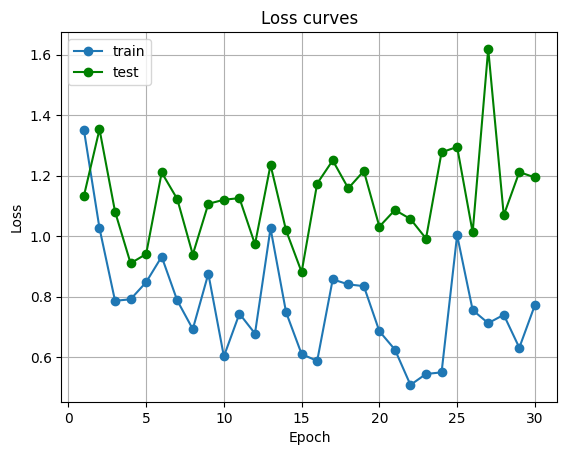

In [33]:
plt.plot(range(1, len(train_losses_rnn) + 1), train_losses_rnn, marker='o', label='train')
plt.plot(range(1, len(test_losses_rnn) + 1), test_losses_rnn, marker='o', label='test', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curves')
plt.legend()
plt.grid(True)

# LSTM

In [47]:
class SimpleLSTM(nn.Module):
    def __init__(self, hidden_size=128, output_size=15):
        super().__init__()
        self.lstm = nn.LSTM(input_size=300, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(128, output_size)

    def forward(self, x):
        out, hidden = self.lstm(x)
        logits = self.fc(hidden[0].squeeze())
        return logits

In [48]:
lstm_model = SimpleLSTM().to(device)
loss_lstm = nn.CrossEntropyLoss()
optimizer_lstm = torch.optim.Adam(lstm_model.parameters())

In [49]:
epochs_lstm = 30

In [50]:
train_losses_lstm = []
test_losses_lstm = []

In [51]:
for i in range(epochs_lstm):
    print(f'Epoch {i}')
    train_loop(train_dataloader, lstm_model, loss_lstm, optimizer_lstm, train_losses_lstm)
    test_loop(test_dataloader, lstm_model, loss_lstm, test_losses_lstm)
    print('-----------------------------------')

Epoch 0
loss: 2.703220 [    4/20342]
loss: 1.158057 [ 6404/20342]
loss: 0.899314 [12804/20342]
loss: 0.806306 [19204/20342]
Test Error: 
f1 score: 0.65, Precision: 0.60, Recall: 0.80, Accuracy: 0.69 | Avg loss: 0.961304
-----------------------------------
Epoch 1
loss: 0.713742 [    4/20342]
loss: 0.478370 [ 6404/20342]
loss: 0.434193 [12804/20342]
loss: 0.459856 [19204/20342]
Test Error: 
f1 score: 0.74, Precision: 0.68, Recall: 0.85, Accuracy: 0.77 | Avg loss: 0.697849
-----------------------------------
Epoch 2
loss: 0.553295 [    4/20342]
loss: 0.448016 [ 6404/20342]
loss: 0.327801 [12804/20342]
loss: 0.451150 [19204/20342]
Test Error: 
f1 score: 0.78, Precision: 0.73, Recall: 0.87, Accuracy: 0.81 | Avg loss: 0.629742
-----------------------------------
Epoch 3
loss: 0.275262 [    4/20342]
loss: 0.242197 [ 6404/20342]
loss: 0.407270 [12804/20342]
loss: 0.319351 [19204/20342]
Test Error: 
f1 score: 0.79, Precision: 0.74, Recall: 0.87, Accuracy: 0.81 | Avg loss: 0.587319
------------

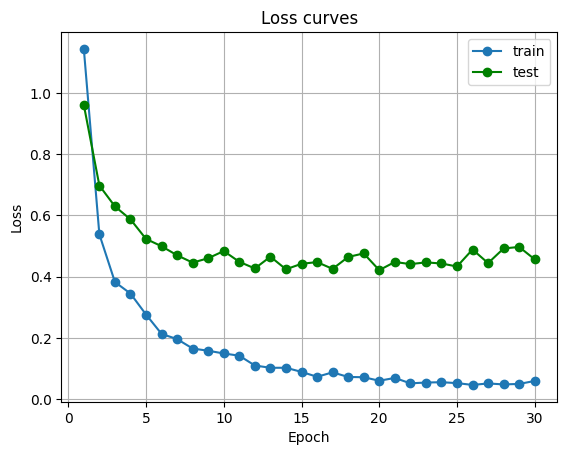

In [52]:
plt.plot(range(1, len(train_losses_lstm) + 1), train_losses_lstm, marker='o', label='train')
plt.plot(range(1, len(test_losses_lstm) + 1), test_losses_lstm, marker='o', label='test', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curves')
plt.legend()
plt.grid(True)

# GRU

In [89]:
class SimpleGRU(nn.Module):
    def __init__(self, hidden_size=128, output_size=15):
        super().__init__()
        self.gru = nn.GRU(input_size=300, hidden_size=hidden_size, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_size * 2, output_size)

    def forward(self, x):
        out, hidden = self.gru(x)
        hidden_cat = torch.cat((hidden[0], hidden[1]), dim=1)
        logits = self.fc(hidden_cat)
        return logits

In [90]:
gru_model = SimpleGRU(hidden_size=256).to(device)
loss_gru = nn.CrossEntropyLoss()
optimizer_gru = torch.optim.Adam(gru_model.parameters())

In [92]:
epochs_gru = 30

In [93]:
train_losses_gru = []
test_losses_gru = []

In [94]:
for i in range(epochs_gru):
    print(f'Epoch {i}')
    train_loop(train_dataloader, gru_model, loss_gru, optimizer_gru, train_losses_gru)
    test_loop(test_dataloader, gru_model, loss_gru, test_losses_gru)
    print('-----------------------------------')

Epoch 0
loss: 2.720240 [    4/20342]
loss: 0.580983 [ 6404/20342]
loss: 0.453096 [12804/20342]
loss: 0.444576 [19204/20342]
Test Error: 
f1 score: 0.77, Precision: 0.71, Recall: 0.87, Accuracy: 0.76 | Avg loss: 0.690769
-----------------------------------
Epoch 1
loss: 0.310667 [    4/20342]
loss: 0.299003 [ 6404/20342]
loss: 0.299287 [12804/20342]
loss: 0.200764 [19204/20342]
Test Error: 
f1 score: 0.81, Precision: 0.77, Recall: 0.88, Accuracy: 0.82 | Avg loss: 0.551869
-----------------------------------
Epoch 2
loss: 0.098991 [    4/20342]
loss: 0.373843 [ 6404/20342]
loss: 0.212695 [12804/20342]
loss: 0.130970 [19204/20342]
Test Error: 
f1 score: 0.82, Precision: 0.78, Recall: 0.88, Accuracy: 0.83 | Avg loss: 0.508618
-----------------------------------
Epoch 3
loss: 0.124057 [    4/20342]
loss: 0.085546 [ 6404/20342]
loss: 0.252042 [12804/20342]
loss: 0.068372 [19204/20342]
Test Error: 
f1 score: 0.83, Precision: 0.79, Recall: 0.88, Accuracy: 0.85 | Avg loss: 0.489594
------------

In [ ]:
plt.plot(range(1, len(train_losses_gru) + 1), train_losses_gru, marker='o', label='train')
plt.plot(range(1, len(test_losses_gru) + 1), test_losses_gru, marker='o', label='test', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curves')
plt.legend()
plt.grid(True)

# Мой GRU

In [46]:
from math import sqrt

In [101]:
class MyGRU(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.k = 1.0 / self.input_size
        
        self.W_z = nn.Parameter(torch.empty(self.hidden_size, self.input_size).uniform_(-sqrt(self.k), sqrt(self.k)))
        self.U_z = nn.Parameter(torch.empty(self.hidden_size, self.hidden_size).uniform_(-sqrt(self.k), sqrt(self.k)))
        self.b_z = nn.Parameter(torch.empty(self.hidden_size).uniform_(-sqrt(self.k), sqrt(self.k)))

        self.W_r = nn.Parameter(torch.empty(self.hidden_size, self.input_size).uniform_(-sqrt(self.k), sqrt(self.k)))
        self.U_r = nn.Parameter(torch.empty(self.hidden_size, self.hidden_size).uniform_(-sqrt(self.k), sqrt(self.k)))
        self.b_r = nn.Parameter(torch.empty(self.hidden_size).uniform_(-sqrt(self.k), sqrt(self.k)))

        self.W_h = nn.Parameter(torch.empty(self.hidden_size, self.input_size).uniform_(-sqrt(self.k), sqrt(self.k)))
        self.U_h = nn.Parameter(torch.empty(self.hidden_size, self.hidden_size).uniform_(-sqrt(self.k), sqrt(self.k)))
        self.b_h = nn.Parameter(torch.empty(self.hidden_size).uniform_(-sqrt(self.k), sqrt(self.k)))


    def forward(self, batch):
        if batch.dim() == 2:
            batch = batch.unsqueeze(0)
            
        batch_size = batch.shape[0]
        outs = [torch.zeros(batch_size, self.hidden_size).to(device)]
        h_n = []
        
        seq_len = batch.shape[1]
        for i in range(seq_len):
            x_i = batch[:, i, :]
            z_t = torch.sigmoid(x_i @ self.W_z.T + outs[-1] @ self.U_z.T + self.b_z)
            r_t = torch.sigmoid(x_i @ self.W_r.T + outs[-1] @ self.U_r.T + self.b_r)
            h_t = z_t * outs[-1] + (1 - z_t) * torch.tanh(x_i @ self.W_h.T + (r_t * outs[-1]) @ self.U_h.T + self.b_h)
            outs.append(h_t)
        output = torch.stack(outs[1:], dim=1)
        h_n = output[:, -1, :]
            
        return output, h_n

In [104]:
myGRU = MyGRU(input_size=300, hidden_size=128).to(device)

In [135]:
def pad_batch(batch):
    sequences, labels, lengths = zip(*batch)
    padded = pad_sequence(sequences, batch_first=True)
    return padded, torch.tensor(labels), torch.tensor(lengths)

In [136]:
train_dataloader_for_my_gru = DataLoader(train_dataset, batch_size, collate_fn=pad_batch, sampler=sampler)
test_dataloader_for_my_gru = DataLoader(test_dataset, batch_size, collate_fn=pad_batch)

In [141]:
class SimpleMyGRU(nn.Module):
    def __init__(self, hidden_size=128, output_size=15):
        super().__init__()
        self.gru = MyGRU(input_size=300, hidden_size=hidden_size)
        self.fc = nn.Linear(128, output_size)

    def forward(self, x):
        out, hidden = self.gru(x)
        logits = self.fc(hidden.squeeze())
        return logits

In [142]:
my_gru_model = SimpleMyGRU().to(device)
loss_my_gru = nn.CrossEntropyLoss()
optimizer_my_gru = torch.optim.Adam(my_gru_model.parameters())

In [143]:
epochs_my_gru = 30

In [144]:
train_losses_my_gru = []
test_losses_my_gru = []

In [145]:
for i in range(epochs_my_gru):
    print(f'Epoch {i}')
    train_loop(train_dataloader_for_my_gru, my_gru_model, loss_my_gru, optimizer_my_gru, train_losses_my_gru)
    test_loop(test_dataloader_for_my_gru, my_gru_model, loss_my_gru, test_losses_my_gru)
    print('-----------------------------------')

Epoch 0
loss: 2.716794 [   64/20342]
loss: 2.686637 [ 6464/20342]
loss: 2.714084 [12864/20342]
loss: 2.684505 [19264/20342]
Test Error: 
f1 score: 0.02, Precision: 0.12, Recall: 0.08, Accuracy: 0.02 | Avg loss: 2.731880
-----------------------------------
Epoch 1
loss: 2.675464 [   64/20342]
loss: 2.419034 [ 6464/20342]
loss: 1.795040 [12864/20342]
loss: 1.240918 [19264/20342]
Test Error: 
f1 score: 0.46, Precision: 0.48, Recall: 0.61, Accuracy: 0.53 | Avg loss: 1.444802
-----------------------------------
Epoch 2
loss: 1.098651 [   64/20342]
loss: 0.584007 [ 6464/20342]
loss: 0.638078 [12864/20342]
loss: 0.294268 [19264/20342]
Test Error: 
f1 score: 0.74, Precision: 0.69, Recall: 0.83, Accuracy: 0.75 | Avg loss: 0.813661
-----------------------------------
Epoch 3
loss: 0.281349 [   64/20342]
loss: 0.574578 [ 6464/20342]
loss: 0.309277 [12864/20342]
loss: 0.333648 [19264/20342]
Test Error: 
f1 score: 0.79, Precision: 0.75, Recall: 0.85, Accuracy: 0.79 | Avg loss: 0.642815
------------

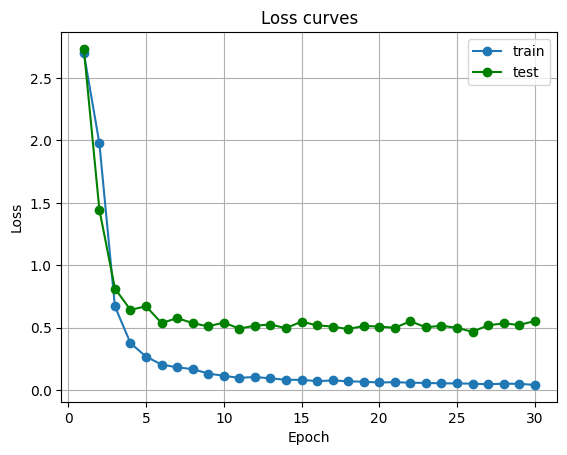

In [146]:
plt.plot(range(1, len(train_losses_my_gru) + 1), train_losses_my_gru, marker='o', label='train')
plt.plot(range(1, len(test_losses_my_gru) + 1), test_losses_my_gru, marker='o', label='test', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curves')
plt.legend()
plt.grid(True)

# Вывод
Лучше всего себя показала модель с блоком GRU. Хуже всех оказалась обычная RNN

| **Model** | **F1-score** | **Precision** | **Recall** | **Accuracy** |
|---|---|---|---| ---|
| **RNN** | 0.64 | 0.59 | 0.74 | 0.71 |
| **LSTM** | **0.86** | 0.84 | **0.89** | 0.88 |
| **GRU** | **0.86** | **0.86** | 0.86 | **0.89** |
| **My GRU** | 0.85 | **0.86** | 0.85 | **0.89** |